         Date    Open    High     Low   Close  Volume  OpenInt
0  15-08-2008  44.886  44.886  44.886  44.886     112        0
1  18-08-2008  44.564  44.564  43.875  43.875   28497        0
2  19-08-2008  43.283  43.283  43.283  43.283     112        0
3  20-08-2008  43.918  43.918  43.892  43.892    4468        0
4  22-08-2008  44.097  44.097  44.017  44.071    4006        0
Total rows: 2325
Training shape: (1800, 60, 1)
Testing shape: (465, 60, 1)


C:\Users\pente\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 60, 64)              │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 60, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step - loss: 0.0420 - val_loss: 0.0046
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - loss: 0.0076 - val_loss: 0.0031
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0063 - val_loss: 0.0011
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 0.0053 - val_loss: 0.0017
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 0.0051 - val_loss: 0.0039
Epoch 6/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 0.0046 - val_loss: 0.0011
Epoch 7/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.0044 - val_loss: 0.0036
Epoch 8/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 0.0038 - val_loss: 0.0034
Epoch 9/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 0.0037 - val_loss: 9.8974e-04
Epoch 10/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 0.0038 - val_loss: 0.0031
Epoch 11/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 0.0031 - val_loss: 0.0063
Epoch 12/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss

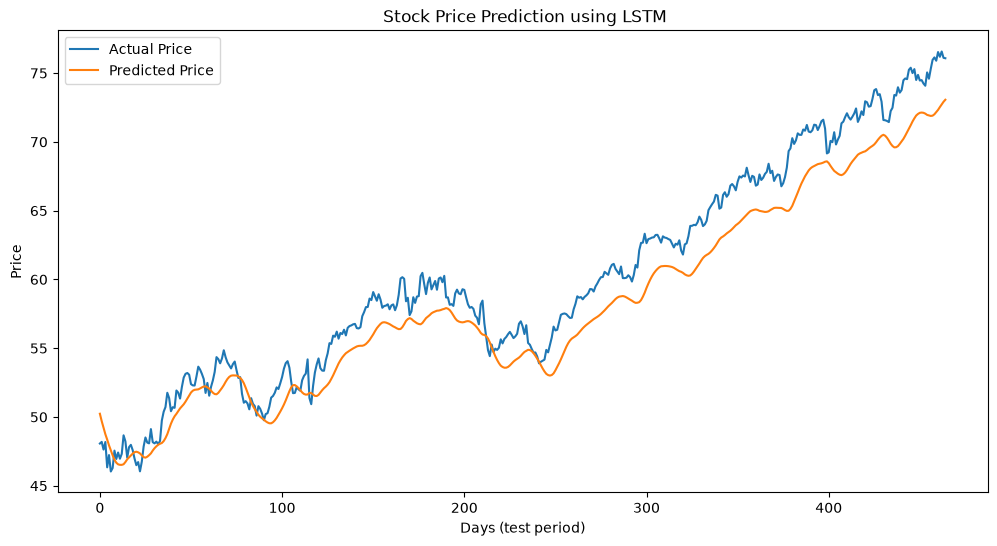

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Predicted next trading day closing price: 73.1714


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras import layers, models

# STEP 1: Dataset
data = pd.read_csv(r"C:\Users\pente\Downloads\stockmarketdata.csv")

print(data.head())
print("Total rows:", len(data))

# We only use the closing price for prediction
close_prices = data[["Close"]].values        # shape (days, 1)

# STEP 2: Scale the data (0 to 1)
# LSTMs train much better when values are small and similar in range.
# The scaler is fitted ONLY on the training part (first 80%) so the
# model never "peeks" at future prices.
train_size = int(0.8 * len(close_prices))

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(close_prices[:train_size])
scaled_data = scaler.transform(close_prices)

# STEP 3: Create windows (60 past days -> next day)
window_size = 60

X = []
y = []
for i in range(window_size, len(scaled_data)):
    X.append(scaled_data[i - window_size:i, 0])   # previous 60 prices
    y.append(scaled_data[i, 0])                   # the price right after

X = np.array(X)
y = np.array(y)

# LSTM expects (samples, time_steps, features)
X = X.reshape(X.shape[0], window_size, 1)

# Split by time (no shuffling): targets before train_size go to training
split = train_size - window_size
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# STEP 4: Build the LSTM model
model = models.Sequential([
    layers.LSTM(64, return_sequences=True, input_shape=(window_size, 1)),
    layers.Dropout(0.2),

    layers.LSTM(32),
    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    # Single output: the predicted (scaled) next-day price
    layers.Dense(1)
])

model.compile(optimizer="adam", loss="mean_squared_error")
model.summary()

# STEP 5: Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    batch_size=32
)


# STEP 6: Predict on the test set and convert back to real prices


predicted_scaled = model.predict(X_test)

predicted_prices = scaler.inverse_transform(predicted_scaled)
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))
print("Test RMSE (in price units):", rmse)

# STEP 7: Plot actual vs predicted prices
plt.figure(figsize=(12, 6))
plt.plot(actual_prices, label="Actual Price")
plt.plot(predicted_prices, label="Predicted Price")
plt.title( " Stock Price Prediction using LSTM")
plt.xlabel("Days (test period)")
plt.ylabel("Price")
plt.legend()
plt.show()

# STEP 8: Predict the NEXT (unseen) day's price
last_60_days = scaled_data[-window_size:]                   # most recent 60 days
last_60_days = last_60_days.reshape(1, window_size, 1)

next_day_scaled = model.predict(last_60_days)
next_day_price = scaler.inverse_transform(next_day_scaled)

print("Predicted next trading day closing price:", next_day_price[0][0])